In [9]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import pandas as pd, matplotlib, matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import time

matplotlib.rcParams['animation.embed_limit'] = 100
np.random.seed(0); torch.manual_seed(0)

DIRS = [(1, 0), (-1, 0), (0, 1), (0, -1)]
LEFT = {0: 2, 1: 3, 2: 1, 3: 0}
RIGHT = {0: 3, 1: 2, 2: 0, 3: 1}
NEXT = [[d, LEFT[d], RIGHT[d]] for d in range(4)]

N_PH = 5
OBS_DIM = 30
PH_NAMES = ['NS прямо+право', 'NS налево', 'WE прямо+право', 'WE налево', 'пешеходы']
CAP = np.array([2, 1, 1])
PCAP, QN, PN, LAM, PW = 6, 30.0, 20.0, 0.3, 1.5

GREEN = np.zeros((N_PH, 4, 3), bool)
GREEN[0, 0:2, 0] = GREEN[0, 0:2, 2] = True
GREEN[1, 0:2, 1] = True
GREEN[2, 2:4, 0] = GREEN[2, 2:4, 2] = True
GREEN[3, 2:4, 1] = True


def shift(a, di, dj):
    H, W = a.shape
    out = np.zeros_like(a)
    si = slice(max(0, -di), H - max(0, di)); ti = slice(max(0, di), H - max(0, -di))
    sj = slice(max(0, -dj), W - max(0, dj)); tj = slice(max(0, dj), W - max(0, -dj))
    out[ti, tj] = a[si, sj]
    return out


class TrafficGridEnv:
    def __init__(self, H=3, W=3, T=200):
        self.H, self.W, self.T, self.n = H, W, T, H * W
        m = np.zeros((H, W, 4))
        m[0, :, 0] = 1; m[H-1, :, 1] = 1; m[:, 0, 2] = 1; m[:, W-1, 3] = 1
        self.entry_mask = m

    def reset(self, scenario, seed=0):
        self.sc = scenario
        self.rng_arr = np.random.default_rng(seed)
        self.rng_turn = np.random.default_rng(seed + 777)
        self.rng_ped = np.random.default_rng(seed + 555)
        jr = np.random.default_rng(scenario['jseed'])
        self.jit = jr.uniform(0.6, 1.4, (self.H, self.W, 4))
        self.jit_p = jr.uniform(0.5, 1.5, (self.H, self.W))
        self.q = np.zeros((self.H, self.W, 4, 3), dtype=int)
        self.p = np.zeros((self.H, self.W), dtype=int)
        self.phase = np.zeros((self.H, self.W), dtype=int)
        self.t = 0
        self.sumq = self.sump = 0
        self.arrived = self.exited = self.arrived_p = self.crossed = 0
        self.switches = self.empty = 0
        return self._obs()

    def _mod(self):
        s = self.sc
        return max(0.0, 1 + s['burst_amp'] * np.sin(2 * np.pi * self.t / s['period'] + s['shift']))

    def _rates(self):
        s = self.sc
        dm = np.array([s['ns_mult']] * 2 + [s['ew_mult']] * 2)
        return self.entry_mask * self.jit * s['base'] * dm * self._mod()

    def _split(self, n):
        s = self.sc
        ps, pl, pr = 1 - s['pl'] - s['pr'], s['pl'], s['pr']
        a = self.rng_turn.binomial(n, ps)
        rest = n - a
        b = self.rng_turn.binomial(rest, pl / (pl + pr))
        return np.stack([a, b, rest - b], -1)

    def _obs(self):
        H, W = self.H, self.W
        qn = np.minimum(self.q, QN) / QN
        qd = np.minimum(self.q.sum(-1), QN) / QN
        gd = GREEN[self.phase][..., 0].astype(float)
        pn = np.minimum(self.p, PN) / PN
        onehot = np.eye(N_PH)[self.phase]
        up_q, up_g, down_q = (np.zeros((H, W, 4)) for _ in range(3))
        for d, (di, dj) in enumerate(DIRS):
            up_q[..., d] = shift(qd[..., d], di, dj)
            up_g[..., d] = shift(gd[..., d], di, dj)
            down_q[..., d] = shift(qd[..., d], -di, -dj)
        obs = np.concatenate([qn.reshape(H, W, 12), pn[..., None], onehot, up_q, up_g, down_q], -1)
        return obs.reshape(self.n, -1).astype(np.float32)

    def step(self, actions):
        H, W = self.H, self.W
        actions = np.asarray(actions).reshape(H, W)
        switched = actions != self.phase
        self.switches += int(switched.sum())
        self.phase = actions.copy()
        ok = ~switched

        green = GREEN[self.phase] & ok[..., None, None]
        flow = np.minimum(self.q, CAP) * green
        self.q = self.q - flow

        incoming = np.zeros((H, W, 4), dtype=int)
        for d in range(4):
            for m in range(3):
                nd = NEXT[d][m]
                f = flow[:, :, d, m]
                moved = shift(f, *DIRS[nd])
                incoming[..., nd] += moved
                self.exited += int(f.sum() - moved.sum())
        arr = self.rng_arr.poisson(self._rates())
        self.arrived += int(arr.sum())
        incoming += arr
        self.q += self._split(incoming)

        ped_green = (self.phase == 4) & ok
        cross = np.minimum(self.p, PCAP) * ped_green
        self.p = self.p - cross
        self.crossed += int(cross.sum())
        pa = self.rng_ped.poisson(self.sc['ped'] * self.jit_p * self._mod())
        self.p += pa
        self.arrived_p += int(pa.sum())

        self.t += 1
        self.sumq += self.q.sum()
        self.sump += self.p.sum()
        self.empty += (self.q == 0).sum()
        return self._obs(), self._reward(), self.t >= self.T

    def _reward(self):
        lane = np.where(self.q == 0, 0.08, -np.minimum(self.q, 30) / 10.0)
        ped = np.where(self.p == 0, 0.25, -np.minimum(self.p, 30) / 10.0)
        r_own = lane.sum((-1, -2)) + PW * ped
        pad = np.pad(r_own, 1); cnt = np.pad(np.ones_like(r_own), 1)
        nb_sum = pad[:-2, 1:-1] + pad[2:, 1:-1] + pad[1:-1, :-2] + pad[1:-1, 2:]
        nb_cnt = cnt[:-2, 1:-1] + cnt[2:, 1:-1] + cnt[1:-1, :-2] + cnt[1:-1, 2:]
        r = (1 - LAM) * r_own + LAM * nb_sum / np.maximum(nb_cnt, 1)
        return r.reshape(-1).astype(np.float32)

    def metrics(self):
        return dict(avg_queue=self.sumq / (self.T * self.n),
                    avg_delay=self.sumq / max(self.arrived, 1),
                    ped_delay=self.sump / max(self.arrived_p, 1),
                    throughput=self.exited,
                    ped_served=self.crossed / max(self.arrived_p, 1),
                    empty_share=self.empty / (self.T * self.n * 12),
                    switches=self.switches / (self.T * self.n))

In [10]:
def sample_scenario(rng):
    mode = rng.choice(['uniform', 'ns', 'ew'], p=[.4, .3, .3])
    ns = ew = 1.0
    if mode == 'ns': ns, ew = rng.uniform(1.3, 2.0), rng.uniform(0.3, 0.8)
    if mode == 'ew': ns, ew = rng.uniform(0.3, 0.8), rng.uniform(1.3, 2.0)
    return dict(base=rng.uniform(0.1, 0.5), ns_mult=ns, ew_mult=ew,
                burst_amp=rng.uniform(0, 0.8), period=rng.uniform(40, 120),
                shift=rng.uniform(0, 2 * np.pi), ped=rng.uniform(0.02, 0.3),
                pl=rng.uniform(0.1, 0.3), pr=rng.uniform(0.1, 0.3),
                jseed=int(rng.integers(10**9)))

def S(base, ns=1., ew=1., amp=0., period=80., shift=0., ped=0.1, pl=0.2, pr=0.2, jseed=1):
    return dict(base=base, ns_mult=ns, ew_mult=ew, burst_amp=amp, period=period,
                shift=shift, ped=ped, pl=pl, pr=pr, jseed=jseed)

NAMED = {
    'low':        S(0.10, ped=0.05, jseed=1),
    'medium':     S(0.25, ped=0.12, jseed=2),
    'high':       S(0.42, ped=0.20, jseed=3),
    'NS-rush':    S(0.35, ns=1.7, ew=0.4, jseed=4),
    'EW-rush':    S(0.35, ns=0.4, ew=1.7, jseed=5),
    'bursty':     S(0.30, amp=0.9, period=50, ped=0.15, jseed=6),
    'ped-heavy':  S(0.20, ped=0.35, jseed=7),
    'left-heavy': S(0.30, pl=0.45, pr=0.10, jseed=8),
    'overload':   S(0.65, ped=0.30, jseed=9),
}

def fixed_policy(env, obs):
    return np.full(env.n, (env.t // 6) % N_PH)

def phase_demand(env):
    ns, we = env.q[:, :, 0:2, :], env.q[:, :, 2:4, :]
    return np.stack([ns[..., [0, 2]].sum((-1, -2)), ns[..., 1].sum(-1),
                     we[..., [0, 2]].sum((-1, -2)), we[..., 1].sum(-1),
                     PW * env.p], -1)

def greedy_policy(env, obs):
    dem = phase_demand(env)
    cur = env.phase
    cur_d = np.take_along_axis(dem, cur[..., None], -1)[..., 0]
    best, best_d = dem.argmax(-1), dem.max(-1)
    return np.where(best_d - cur_d > 2, best, cur).reshape(-1)

def random_policy(env, obs):
    return np.random.randint(0, N_PH, env.n)

def run_episode(env, policy, scenario, seed, record=False):
    obs = env.reset(scenario, seed)
    hist = dict(q=[], p=[], phase=[])
    done = False
    while not done:
        obs, r, done = env.step(policy(env, obs))
        if record:
            hist['q'].append(env.q.copy()); hist['p'].append(env.p.copy()); hist['phase'].append(env.phase.copy())
    return env.metrics(), hist

In [11]:
class SharedDQN:
    def __init__(self, obs_dim=OBS_DIM, n_act=N_PH, lr=1e-3, gamma=0.95, tau=0.01, cap=300_000):
        mk = lambda: nn.Sequential(nn.Linear(obs_dim, 128), nn.ReLU(),
                                   nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, n_act))
        self.q, self.tgt = mk(), mk()
        self.tgt.load_state_dict(self.q.state_dict())
        self.opt = torch.optim.Adam(self.q.parameters(), lr=lr)
        self.gamma, self.tau, self.cap, self.n_act = gamma, tau, cap, n_act
        self.O = np.zeros((cap, obs_dim), np.float32); self.O2 = np.zeros((cap, obs_dim), np.float32)
        self.A = np.zeros(cap, np.int64); self.R = np.zeros(cap, np.float32)
        self.ptr = self.size = 0

    def act(self, obs, eps=0.0):
        with torch.no_grad():
            a = self.q(torch.from_numpy(obs)).argmax(1).numpy()
        if eps > 0:
            cur = obs[:, 13:18].argmax(1)
            rand_a = np.where(np.random.rand(len(a)) < 0.6, cur, np.random.randint(0, self.n_act, len(a)))
            rnd = np.random.rand(len(a)) < eps
            a[rnd] = rand_a[rnd]
        return a

    def push(self, o, a, r, o2):
        idx = (self.ptr + np.arange(len(o))) % self.cap
        self.O[idx], self.A[idx], self.R[idx], self.O2[idx] = o, a, r, o2
        self.ptr = (self.ptr + len(o)) % self.cap
        self.size = min(self.size + len(o), self.cap)

    def learn(self, bs=256):
        i = np.random.randint(0, self.size, bs)
        o, o2 = torch.from_numpy(self.O[i]), torch.from_numpy(self.O2[i])
        a, r = torch.from_numpy(self.A[i]), torch.from_numpy(self.R[i])
        q = self.q(o).gather(1, a[:, None]).squeeze(1)
        with torch.no_grad():
            a2 = self.q(o2).argmax(1, keepdim=True)
            y = r + self.gamma * self.tgt(o2).gather(1, a2).squeeze(1)
        loss = F.smooth_l1_loss(q, y)
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), 5.0); self.opt.step()
        for p, tp in zip(self.q.parameters(), self.tgt.parameters()):
            tp.data.mul_(1 - self.tau).add_(self.tau * p.data)

agent = SharedDQN()
dqn_policy = lambda env, obs: agent.act(obs, 0.0)

эпизод  25 | eps=0.92 | ср. награда=-1.623 | задержка RL=32.30 (жадная=26.55) |   15 c
эпизод  50 | eps=0.84 | ср. награда=-1.375 | задержка RL=26.19 (жадная=26.55) |   30 c
эпизод  75 | eps=0.75 | ср. награда=-1.424 | задержка RL=22.39 (жадная=26.55) |   45 c
эпизод 100 | eps=0.67 | ср. награда=-0.965 | задержка RL=22.93 (жадная=26.55) |   61 c
эпизод 125 | eps=0.59 | ср. награда=-0.618 | задержка RL=22.38 (жадная=26.55) |   76 c
эпизод 150 | eps=0.50 | ср. награда=-0.680 | задержка RL=20.57 (жадная=26.55) |   91 c
эпизод 175 | eps=0.42 | ср. награда=-0.726 | задержка RL=20.90 (жадная=26.55) |  106 c
эпизод 200 | eps=0.34 | ср. награда=-0.364 | задержка RL=21.61 (жадная=26.55) |  121 c
эпизод 225 | eps=0.25 | ср. награда=-0.378 | задержка RL=21.14 (жадная=26.55) |  136 c
эпизод 250 | eps=0.17 | ср. награда= 0.043 | задержка RL=20.88 (жадная=26.55) |  151 c
эпизод 275 | eps=0.09 | ср. награда=-0.335 | задержка RL=20.18 (жадная=26.55) |  166 c
эпизод 300 | eps=0.05 | ср. награда=-0.315 

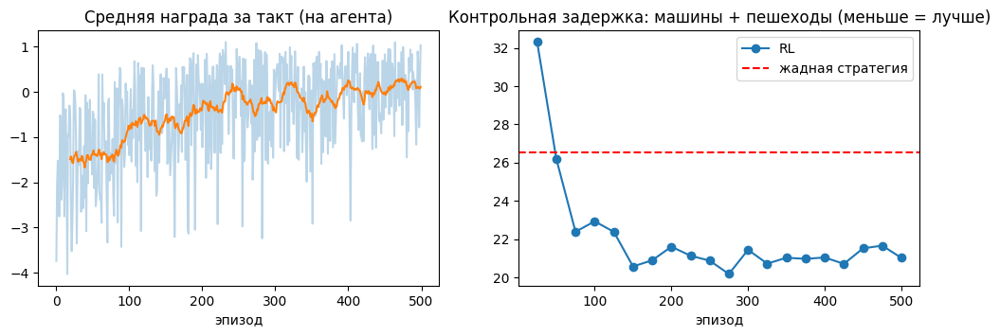

In [12]:
EPISODES, T_TRAIN = 500, 200
GRIDS = [(3, 3), (3, 4), (4, 4)]
rng = np.random.default_rng(42)

def quick_eval(policy):
    res = []
    for k, name in enumerate(['medium', 'high', 'NS-rush', 'ped-heavy']):
        m = run_episode(TrafficGridEnv(3, 3, 200), policy, NAMED[name], 5000 + k)[0]
        res.append(m['avg_delay'] + m['ped_delay'])
    return np.mean(res)

greedy_ref = quick_eval(greedy_policy)
log_ret, log_eval = [], []
t0 = time.time()

for ep in range(EPISODES):
    eps = max(0.05, 1 - ep / (0.6 * EPISODES))
    H, W = GRIDS[ep % len(GRIDS)]
    env = TrafficGridEnv(H, W, T_TRAIN)
    obs = env.reset(sample_scenario(rng), seed=int(rng.integers(10**6)))
    done, ret = False, 0.0
    while not done:
        a = agent.act(obs, eps)
        obs2, r, done = env.step(a)
        agent.push(obs, a, r / 4.0, obs2)
        obs = obs2; ret += r.mean()
        if agent.size > 2000 and env.t % 2 == 0:
            agent.learn()
    log_ret.append(ret / T_TRAIN)
    if (ep + 1) % 25 == 0:
        qe = quick_eval(dqn_policy); log_eval.append((ep + 1, qe))
        print(f'эпизод {ep+1:3d} | eps={eps:.2f} | ср. награда={np.mean(log_ret[-25:]):6.3f} '
              f'| задержка RL={qe:5.2f} (жадная={greedy_ref:5.2f}) | {time.time()-t0:4.0f} c')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(log_ret, alpha=.3); ax[0].plot(pd.Series(log_ret).rolling(20).mean())
ax[0].set_title('Средняя награда за такт (на агента)'); ax[0].set_xlabel('эпизод')
ev = np.array(log_eval)
ax[1].plot(ev[:, 0], ev[:, 1], 'o-', label='RL')
ax[1].axhline(greedy_ref, color='r', ls='--', label='жадная стратегия')
ax[1].set_title('Контрольная задержка: машины + пешеходы (меньше = лучше)')
ax[1].set_xlabel('эпизод'); ax[1].legend()
plt.show()

Среднее ожидание машины (такты), меньше = лучше:


policy,RL (DQN),Жадная,Случайная,Таймер
scenario,,,,
low,7.80,26.31,88.84,23.36
medium,11.93,17.70,107.57,25.01
high,25.88,23.40,124.33,31.33
NS-rush,20.21,19.88,123.39,39.96
EW-rush,15.16,17.27,121.00,33.59
bursty,15.94,19.70,122.86,28.43
ped-heavy,13.29,22.09,101.97,24.01
left-heavy,16.38,19.28,114.13,31.95
overload,50.86,51.41,133.11,54.70


Среднее ожидание пешехода (такты), меньше = лучше:


policy,RL (DQN),Жадная,Случайная,Таймер
scenario,,,,
low,2.39,10.46,26.99,11.62
medium,4.67,6.28,37.47,11.72
high,5.57,7.79,44.59,11.95
NS-rush,8.75,12.56,32.03,11.74
EW-rush,7.28,9.71,29.26,11.84
bursty,5.94,6.82,44.81,11.78
ped-heavy,2.69,2.98,71.91,12.09
left-heavy,7.36,8.42,33.21,11.94
overload,6.19,22.56,61.78,12.20


avg_delay  ped_delay  avg_queue  throughput  ped_served  \
grid policy                                                               
2x5  RL (DQN)      14.622      6.701      6.734     1117.55       0.980   
     Жадная        20.741     12.696      8.261     1118.40       0.955   
     Случайная    112.973     35.493     47.213      325.15       0.846   
     Таймер        28.872     11.814     12.388     1036.10       0.998   
3x3  RL (DQN)      16.566      6.773      7.530      965.15       0.972   
     Жадная        21.474     13.139      8.544      975.05       0.947   
     Случайная    113.969     37.335     46.443      272.20       0.843   
     Таймер        30.703     11.384     13.000      894.00       0.997   
4x4  RL (DQN)      21.913      6.524      7.515     1254.20       0.978   
     Жадная        28.014     12.737      8.300     1273.60       0.957   
     Случайная    122.478     35.479     37.402      299.95       0.837   
     Таймер        37.358     11.832     11.923     1163.95       0.997   
5x5  RL (DQN)      24.885      6.190      6.530     1496.65       0.978   
     Жадная        33.734     12.765      7.785     1504.05       0.949   
     Случайная    126.675     36.143     29.760      335.70       0.839   
     Таймер        42.755     11.864     10.531     1367.90       0.996   

                empty_share  switches  
grid policy                            
2x5  RL (DQN)         0.693     0.401  
     Жадная           0.587     0.245  
     Случайная        0.419     0.801  
     Таймер           0.589     0.163  
3x3  RL (DQN)         0.684     0.395  
     Жадная           0.585     0.250  
     Случайная        0.422     0.801  
     Таймер           0.578     0.163  
4x4  RL (DQN)         0.689     0.397  
     Жадная           0.595     0.247  
     Случайная        0.493     0.801  
     Таймер           0.596     0.163  
5x5  RL (DQN)         0.708     0.403  
     Жадная           0.608     0.241  
     Случайная        0.543     0.802  
     Таймер           0.617     0.163

Доля сценариев, где RL лучше жадной стратегии:


,машины,пешеходы
grid,,
2x5,0.90,1.0
3x3,0.85,1.0
4x4,0.70,1.0
5x5,0.80,1.0


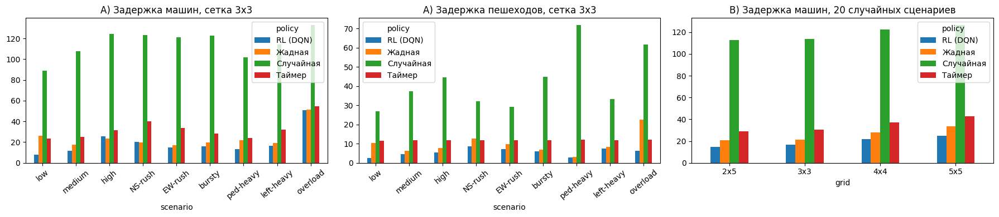

In [13]:
POLICIES = {'RL (DQN)': dqn_policy, 'Жадная': greedy_policy, 'Таймер': fixed_policy, 'Случайная': random_policy}
T_EVAL = 300

def evaluate_suite(H, W, scenarios, seeds):
    rows = []
    for sname, sc in scenarios.items():
        for seed in seeds:
            for pname, pol in POLICIES.items():
                m, _ = run_episode(TrafficGridEnv(H, W, T_EVAL), pol, sc, seed)
                rows.append(dict(grid=f'{H}x{W}', scenario=sname, policy=pname, seed=seed, **m))
    return pd.DataFrame(rows)

order = list(NAMED)
dfA = evaluate_suite(3, 3, NAMED, seeds=range(10_000, 10_008))
tabA_car = dfA.pivot_table(index='scenario', columns='policy', values='avg_delay').loc[order]
tabA_ped = dfA.pivot_table(index='scenario', columns='policy', values='ped_delay').loc[order]
print('Среднее ожидание машины (такты), меньше = лучше:'); display(tabA_car.round(2))
print('Среднее ожидание пешехода (такты), меньше = лучше:'); display(tabA_ped.round(2))

rng_val = np.random.default_rng(999)
rand_sc = {f'rnd{k}': sample_scenario(rng_val) for k in range(20)}
dfB = pd.concat([evaluate_suite(H, W, rand_sc, seeds=[20_000]) for H, W in [(3, 3), (4, 4), (2, 5), (5, 5)]])
cols = ['avg_delay', 'ped_delay', 'avg_queue', 'throughput', 'ped_served', 'empty_share', 'switches']
display(dfB.groupby(['grid', 'policy'])[cols].mean().round(3))

wc = dfB.pivot_table(index=['grid', 'scenario'], columns='policy', values='avg_delay')
wp = dfB.pivot_table(index=['grid', 'scenario'], columns='policy', values='ped_delay')
print('Доля сценариев, где RL лучше жадной стратегии:')
display(pd.DataFrame({'машины': (wc['RL (DQN)'] < wc['Жадная']).groupby('grid').mean(),
                      'пешеходы': (wp['RL (DQN)'] < wp['Жадная']).groupby('grid').mean()}).round(2))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
tabA_car.plot.bar(ax=ax[0], rot=40); ax[0].set_title('A) Задержка машин, сетка 3x3')
tabA_ped.plot.bar(ax=ax[1], rot=40); ax[1].set_title('A) Задержка пешеходов, сетка 3x3')
dfB.pivot_table(index='grid', columns='policy', values='avg_delay').plot.bar(ax=ax[2], rot=0)
ax[2].set_title('B) Задержка машин, 20 случайных сценариев')
plt.tight_layout(); plt.show()

RL     : {'avg_queue': np.float64(8.74), 'avg_delay': np.float64(16.33), 'ped_delay': np.float64(8.18), 'throughput': 607, 'ped_served': 0.94, 'empty_share': np.float64(0.6), 'switches': 0.36}
Жадная : {'avg_queue': np.float64(9.15), 'avg_delay': np.float64(17.09), 'ped_delay': np.float64(9.72), 'throughput': 627, 'ped_served': 0.96, 'empty_share': np.float64(0.54), 'switches': 0.3}
Таймер : {'avg_queue': np.float64(15.57), 'avg_delay': np.float64(29.06), 'ped_delay': np.float64(10.75), 'throughput': 509, 'ped_served': 0.99, 'empty_share': np.float64(0.54), 'switches': 0.16}


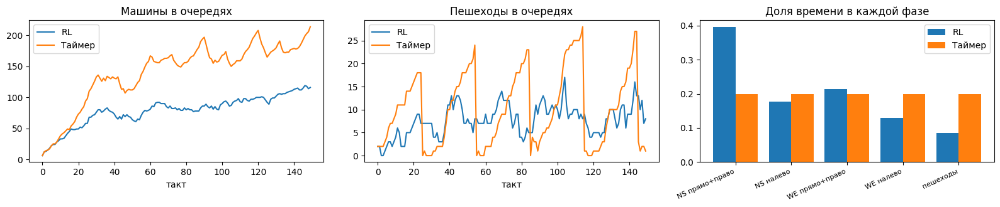

In [15]:
from matplotlib.patches import Rectangle, Circle
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

UD = [(0, 1), (0, -1), (-1, 0), (1, 0)]
RD = [(-1, 0), (1, 0), (0, -1), (0, 1)]
LAT = {1: .25, 0: .65, 2: 1.05}
CAR_COL = {0: '#1f77b4', 1: '#ff7f0e', 2: '#9467bd'}
CORN = [(1, 1), (1, -1), (-1, 1), (-1, -1)]
SHORT = ['NS', 'NS ←', 'WE', 'WE ←', 'ПЕШЕХОДЫ']
HALF, STOP, START, STEP, MAXV, GAP = 1.25, 1.95, 2.2, .75, 6, 9.0
EXT = GAP * .8
RED, GRN = '#e53935', '#00c853'

def rect(cx, cy, w, h):
    return Rectangle((cx - w / 2, cy - h / 2), w, h)

def draw_state(ax, q, p, phase, title):
    H, W = phase.shape
    ax.clear(); ax.set_aspect('equal'); ax.axis('off')
    for i in range(H):
        ax.add_patch(Rectangle((-EXT, -i * GAP - HALF), (W - 1) * GAP + 2 * EXT, 2 * HALF, color='#d0d0d0', zorder=0))
    for j in range(W):
        ax.add_patch(Rectangle((j * GAP - HALF, -(H - 1) * GAP - EXT), 2 * HALF, (H - 1) * GAP + 2 * EXT, color='#d0d0d0', zorder=0))

    cars, car_col, stops, stop_col, zebra, zebra_col = [], [], [], [], [], []
    ped_xy = []
    for i in range(H):
        for j in range(W):
            cx, cy = j * GAP, -i * GAP
            ph = phase[i, j]
            ped_green = ph == 4
            ax.add_patch(Rectangle((cx - HALF, cy - HALF), 2 * HALF, 2 * HALF, color='#8d8d8d', zorder=1))
            ax.text(cx, cy + .22, SHORT[ph], fontsize=6.5, ha='center', va='center', color='white', weight='bold', zorder=6)
            ax.text(cx, cy - .3, f'пеш: {int(p[i, j])}', fontsize=6.5, ha='center', va='center', color='#ffd1e3', zorder=6)

            for d in range(4):
                ux, uy = UD[d]; rx, ry = RD[d]
                vertical = d < 2
                ax.plot([cx + ux * HALF, cx + ux * EXT], [cy + uy * HALF, cy + uy * EXT],
                        color='#f5c400', lw=.8, ls='--', zorder=1)
                for lat in (-1.0, -.5, 0, .5, 1.0):
                    zx = cx + ux * (HALF + .3) + rx * lat
                    zy = cy + uy * (HALF + .3) + ry * lat
                    zebra.append(rect(zx, zy, .22 if vertical else .6, .6 if vertical else .22))
                    zebra_col.append('#7CFC00' if ped_green else 'white')
                for m in range(3):
                    lat = LAT[m]
                    sx = cx + ux * STOP + rx * lat; sy = cy + uy * STOP + ry * lat
                    stops.append(rect(sx, sy, .38 if vertical else .12, .12 if vertical else .38))
                    stop_col.append(GRN if GREEN[ph, d, m] else RED)
                    n = int(q[i, j, d, m])
                    for k in range(min(n, MAXV)):
                        px = cx + ux * (START + STEP * k) + rx * lat
                        py = cy + uy * (START + STEP * k) + ry * lat
                        cars.append(rect(px, py, .32 if vertical else .6, .6 if vertical else .32))
                        car_col.append(CAR_COL[m])
                    if n > MAXV:
                        dist = START + STEP * MAXV + .1
                        ax.text(cx + ux * dist + rx * lat, cy + uy * dist + ry * lat, f'+{n - MAXV}',
                                fontsize=6, ha='center', va='center', color='crimson', weight='bold', zorder=7)

            for sx, sy in CORN:
                ax.add_patch(Circle((cx + sx * 1.6, cy + sy * 1.6), .24, facecolor=GRN if ped_green else RED,
                                    edgecolor='black', lw=.8, zorder=5))
                ax.text(cx + sx * 1.6, cy + sy * 1.6, 'P', fontsize=5.5, ha='center', va='center', color='white', weight='bold', zorder=6)
            for k in range(min(int(p[i, j]), 12)):
                sx, sy = CORN[k % 4]; idx = k // 4
                ped_xy.append((cx + sx * (2.2 + .3 * idx), cy + sy * 2.1))

    ax.add_collection(PatchCollection(zebra, facecolors=zebra_col, edgecolors='none', zorder=2))
    ax.add_collection(PatchCollection(cars, facecolors=car_col, edgecolors='black', linewidths=.4, zorder=3))
    ax.add_collection(PatchCollection(stops, facecolors=stop_col, edgecolors='black', linewidths=.6, zorder=4))
    if ped_xy:
        pp = np.array(ped_xy)
        ax.scatter(pp[:, 0], pp[:, 1], s=38, color='#e91e63', edgecolor='white', linewidth=.8, zorder=5)
    ax.set_xlim(-EXT - .5, (W - 1) * GAP + EXT + .5)
    ax.set_ylim(-(H - 1) * GAP - EXT - .5, EXT + .5)
    ax.set_title(f'{title}\nмашин: {int(q.sum())} | пешеходов: {int(p.sum())}', fontsize=11)

legend = [Patch(facecolor='#1f77b4', edgecolor='k', label='машина: прямо'),
          Patch(facecolor='#ff7f0e', edgecolor='k', label='машина: налево'),
          Patch(facecolor='#9467bd', edgecolor='k', label='машина: направо'),
          Patch(facecolor=GRN, edgecolor='k', label='стоп-линия зелёная: машинам можно'),
          Patch(facecolor=RED, edgecolor='k', label='стоп-линия красная: машинам стоять'),
          Line2D([], [], marker='o', color='w', markerfacecolor='#e91e63', markeredgecolor='white', markersize=9, label='пешеход (ждёт)'),
          Line2D([], [], marker='o', color='w', markerfacecolor=RED, markeredgecolor='k', markersize=10, label='P: светофор пешеходов'),
          Patch(facecolor='#7CFC00', edgecolor='k', label='зебра зелёная: пешеходы идут')]

H, W, T_ANIM = 3, 3, 150
scenario, seed = NAMED['NS-rush'], 123
mA, hA = run_episode(TrafficGridEnv(H, W, T_ANIM), dqn_policy, scenario, seed, record=True)
mB, hB = run_episode(TrafficGridEnv(H, W, T_ANIM), fixed_policy, scenario, seed, record=True)
mC, _ = run_episode(TrafficGridEnv(H, W, T_ANIM), greedy_policy, scenario, seed)
print('RL     :', {k: round(v, 2) for k, v in mA.items()})
print('Жадная :', {k: round(v, 2) for k, v in mC.items()})
print('Таймер :', {k: round(v, 2) for k, v in mB.items()})

fig, axes = plt.subplots(1, 2, figsize=(15, 8.2))
fig.legend(handles=legend, loc='lower center', ncol=4, fontsize=8, frameon=False)
fig.subplots_adjust(bottom=.12, top=.93, left=.02, right=.98, wspace=.05)

def update(t):
    draw_state(axes[0], hA['q'][t], hA['p'][t], hA['phase'][t], f'RL-светофоры (t={t})')
    draw_state(axes[1], hB['q'][t], hB['p'][t], hB['phase'][t], f'Таймер (t={t})')

anim = animation.FuncAnimation(fig, update, frames=T_ANIM, interval=200)
plt.close(fig)
display(HTML(anim.to_jshtml()))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
ax[0].plot([q.sum() for q in hA['q']], label='RL'); ax[0].plot([q.sum() for q in hB['q']], label='Таймер')
ax[0].set_title('Машины в очередях'); ax[0].set_xlabel('такт'); ax[0].legend()
ax[1].plot([x.sum() for x in hA['p']], label='RL'); ax[1].plot([x.sum() for x in hB['p']], label='Таймер')
ax[1].set_title('Пешеходы в очередях'); ax[1].set_xlabel('такт'); ax[1].legend()
share = lambda h: np.bincount(np.concatenate([x.ravel() for x in h['phase']]), minlength=N_PH) / (T_ANIM * H * W)
x = np.arange(N_PH)
ax[2].bar(x - .2, share(hA), .4, label='RL'); ax[2].bar(x + .2, share(hB), .4, label='Таймер')
ax[2].set_xticks(x); ax[2].set_xticklabels(PH_NAMES, rotation=25, ha='right', fontsize=8)
ax[2].set_title('Доля времени в каждой фазе'); ax[2].legend()
plt.tight_layout(); plt.show()